In [1]:
import easyocr
reader = easyocr.Reader(['en']) # this needs to run only once to load the model into memory
# https://github.com/JaidedAI/EasyOCR

Neither CUDA nor MPS are available - defaulting to CPU. Note: This module is much faster with a GPU.


In [ ]:
import fitz #pymupdf -> legacy version but it is what I'm used to
import numpy as np
from textwrap import fill

In [ ]:
doc = fitz.open('../data/CO715-1.pdf') # read pdf type - specific to pdf documents

limit = 5 # no. of pages to go til

In [ ]:

for i, page in enumerate(doc):
    if i >= limit:
        break
    pix = page.get_pixmap(matrix=fitz.Matrix(2, 2)) # zoom in 2
    img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    result = reader.readtext(img)
    
    full_text = " ".join(text for _, text, _ in result)
    
    wrap_ard = 60

    print(f"\n{'='*wrap_ard}")
    print(f"PAGE {i+1}")
    print('='*wrap_ard)
    print(fill(full_text, width=wrap_ard))

# issue of orientation - skew detection and correction
# segmentation of continuous areas of text
# correcting for spelling errors; 
# being mindful of the original language and hw much overcorrection can be done
# balance between fidelity and accomplishment

c:\Users\Acer\hist-hack\.venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



PAGE 1
PUBIzIc RRaRD FFICE 718 cO 715 1 NOTICES THESE   COPIES
ARE   SUPPLIED, FOR 'INFORMATION , AND RESEARCH  ONLY NO (
REPRODUCTION OF THESE NEGATIVES, OR OF PRINTS FROM THEM; MAY
BE MADE FOR PUBLICATION: WITNOUT , THE ASSENT' OF THE
PUBLIC RECORD OFFICE:

PAGE 2
puBIIG RCORD @ppIcF THE WRITING IN ThIS VOLUME IS tOO
CLOSELY BOUND INTO THE VOLUME To REPRODUCE IN ENTIRETY

PAGE 3
14 :C | 1 1 1 1 1 ofore i 1910, F 8 0 1 d 8 1 9 U 1 2 8

PAGE 4
buu 2 1} JOHORE IN IGIO Generel. ~The State of Johore is
situated at the extreme south of the Malay Peninsula and
extends in area to about 9,oo square miles: It is bounded on
the north by the Settle- 1 1 ment of Malacca and by Negri
Sembilan and Taha"g, States of the Federated Malay States,
On the south by 1 wartol strait separating it from the
island of Singapore, on the east by thc China Sea, and on
ilc west by (he Straits of Malacca. 1 The country is for the
mnost pirt fat, although many isolated ranges of hills rise
to height of from three t

In [ ]:
### for addressing orientation of diff text

# Option 1 - doctr

from doctr.io import DocumentFile
from doctr.models import ocr_predictor
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

c:\Users\Acer\hist-hack\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:

model = ocr_predictor(pretrained=True, assume_straight_pages=False)


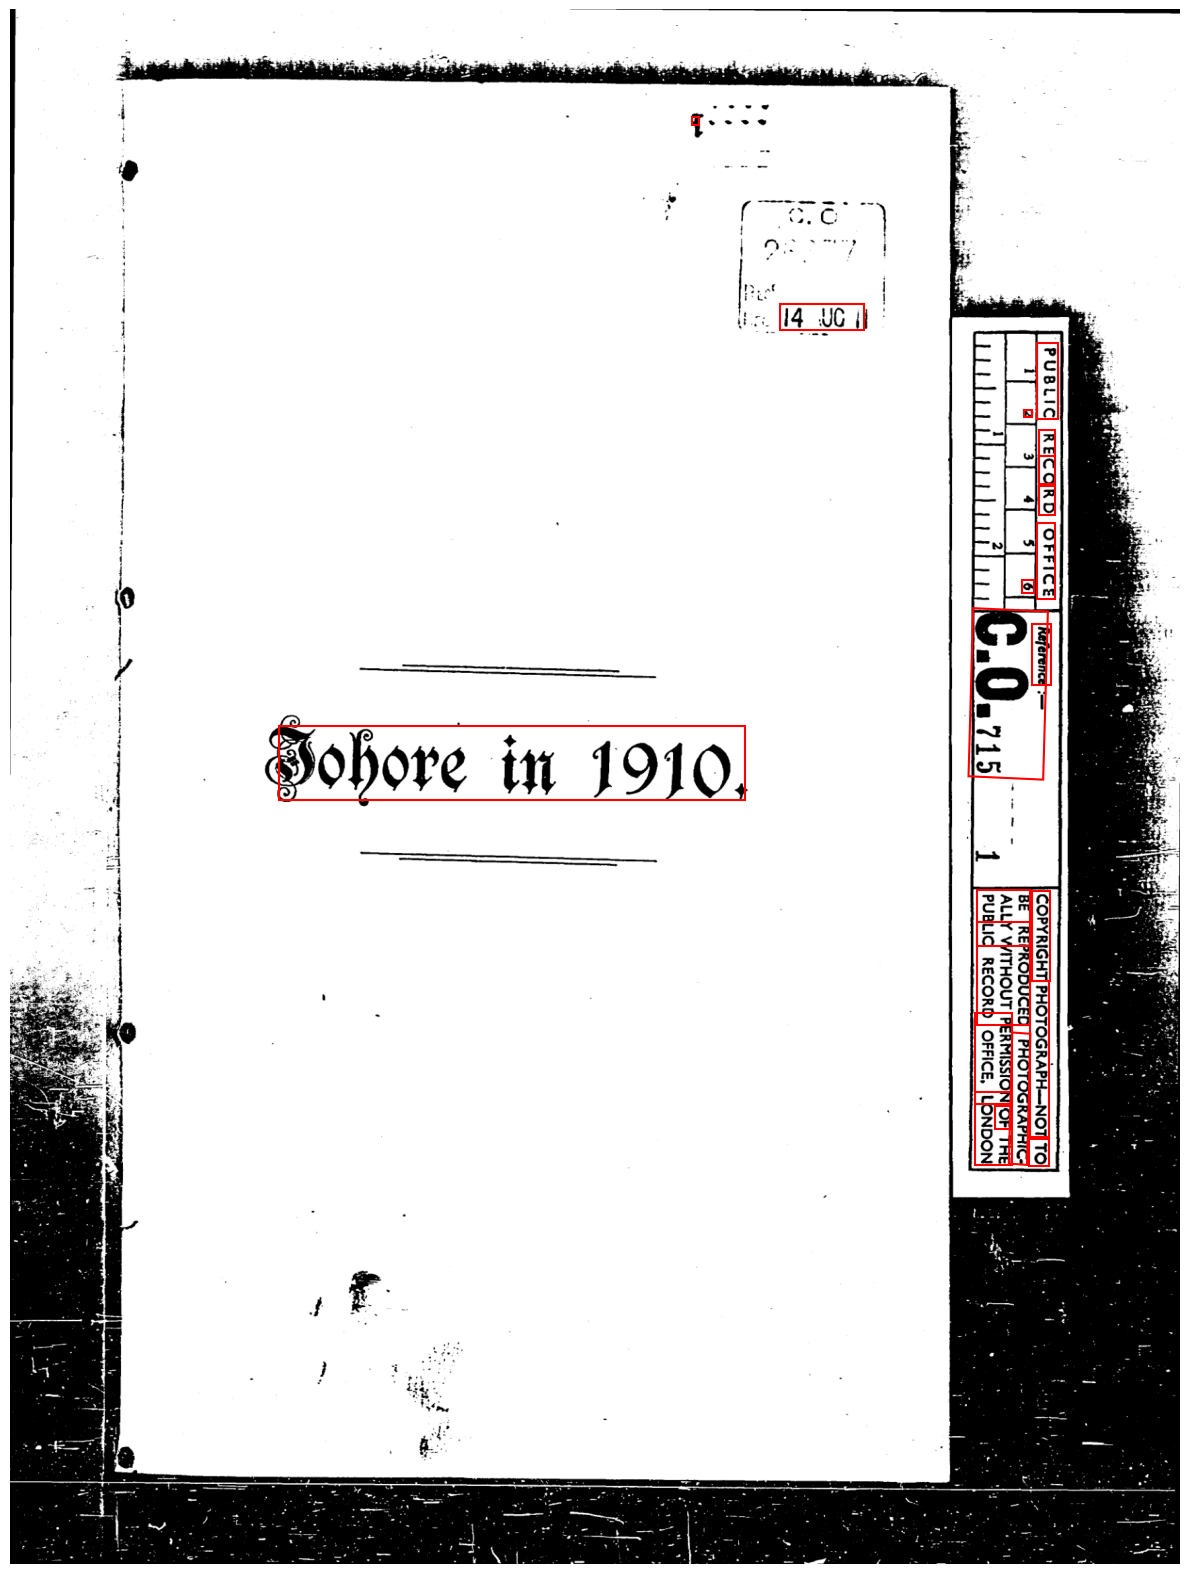

In [ ]:

page_idx = 2 ### page_num - 1 (rmb 0 idx)
doc = fitz.open('../data/CO715-1.pdf') # use fitz for selective opening (lazy loading)
pix = doc[page_idx].get_pixmap(matrix=fitz.Matrix(2, 2))
img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)

# doctr expects a list of pages
result = model([img])

page = result.pages[0]
h, w = img.shape[:2]

fig, ax = plt.subplots(figsize=(12, 16))
ax.imshow(img)

for block in page.blocks:
    for line in block.lines:
        geo = np.array(line.geometry)
        pts = (geo * [w, h]).astype(int)
        rect = patches.Polygon(pts, linewidth=1.5, edgecolor='red', facecolor='none')
        ax.add_patch(rect)

ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Option 2 - paddlOCR (since we're all agentic nw)
from paddleocr import PaddleOCR

page_idx = 2 ### page_num - 1 (rmb 0 idx)
doc = fitz.open('../data/CO715-1.pdf') # use fitz for selective opening (lazy loading)
pix = doc[page_idx].get_pixmap(matrix=fitz.Matrix(2, 2))
img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)


c:\Users\Acer\hist-hack\.venv\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `DISABLE_MODEL_SOURCE_CHECK` to `True`.


In [ ]:
import os
os.environ["FLAGS_use_mkldnn"] = "0"
DEVICE = 'cpu'
ocr = PaddleOCR(use_textline_orientation=True, lang='en', device = DEVICE)
try:
    result = ocr.predict(img)
except Exception as e:
    print(e) # unfortunate

Creating model: ('PP-LCNet_x1_0_doc_ori', None)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Acer\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.
c:\Users\Acer\hist-hack\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('UVDoc', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Acer\.paddlex\official_models\UVDoc`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Acer\.paddlex\official_models\PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv5_server_det', None)
Model files already exist. Using cached files. To redownl

In [ ]:
## Option 3 - Surya-OCR : dependencies will have to be older; prob another branch


In [ ]:
doc = fitz.open('../data/handwritten_persia.pdf') # read pdf type - specific to pdf documents

limit = 1 # no. of pages to go til

# yeah this one .... hard enough for humans my God

for i, page in enumerate(doc):
    if i >= limit:
        break
    pix = page.get_pixmap(matrix=fitz.Matrix(2, 2)) # zoom in 2
    img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    result = reader.readtext(img)
    
    full_text = " ".join(text for _, text, _ in result)
    
    wrap_ard = 60

    print(f"\n{'='*wrap_ard}")
    print(f"PAGE {i+1}")
    print('='*wrap_ard)
    print(fill(full_text, width=wrap_ard))

c:\Users\Acer\hist-hack\.venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



PAGE 1
1 222 ~ep @pie % €& Egnyees Afovific ytenen to Is Omo Coffw
( GsxBxy) 8s c6 s-fonf?o fo sebefrflnt Ooorc 60 "77738767
(fm xee f 8si ~xwf8s 1s68-187 Jn mame mmF8m- Apron Cjo8f
faxfg8 &2 688 Eaow9 f8p Bswgse , Saut' ~RPomfo8 m Fonf2s w
o1 Bcf (xo.@offan mon Rp8 €o 6c f~yv €o f83 Toyik ~Faf(5o
Cso(6arazetrzeer] fpcs' 2a1cfkbr . 9i8 notmtr mb an 89 fo 9
mam % $ Tamob %x fs mfrm f992f&ee Eme/nceos; 6o 'fatmmn8 &
wY ~90 f88m (mxpnta On c I e Bexyati f99 (Exk ~aks,o1 M My 0
1897 c mn Joer,' € P2 fo -9 Ip 98488~ Lp ffsm w_ b ppon romp
Ecwnf mnf &8 +88 w €(19 -8n6f Gesm {1e8  &nee ~O xjvitk
635,4 wct f8r J yoba uwrtolfis fo sv (&i8 fBun8, fo Lilsmt
ou Sv ( xwuff, 781862 fo ~tolesr / Ace 2778829c816- n8' ,
+8s (&s EC6E Eace Cans O2' onmitt MP cmg Jomiona}
~clfowgEs^+ 6& '$keacc t16 nv J E88 7i8_ScG1f B- st &8r6 w8
6tis 489 4i0 eteces W (ngs 48 '+89zf~0 4+, Fo #e OoAdxvo 48
awo ff sx offsr biifmes fgat ~ipj I1T fo Fes (ia n Csxmi (
mL(hme Ein €r {4~6" Tam Mo [  90 f g9an ~Jfr , M Lfa1 7/n